# Segmentation clients — RFM et clustering

**Objectif** : regrouper les clients en segments homogènes pour construire 3 personas et 3 campagnes marketing chiffrées.

- **R**écence : nombre de jours depuis la dernière commande (plus c'est petit, mieux c'est)
- **F**réquence : nombre de commandes
- **M**ontant : total dépensé (produits + frais de port)

Source : table `mart.rfm`, calculée par le pipeline (`sql/03_mart.sql`) à partir du schéma `clean`.
Un client = un `customer_unique_id` (et non `customer_id`, qui change à chaque commande).

In [2]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler
from sqlalchemy import create_engine

# On se place à la racine du projet pour que le fichier .env soit trouvé
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

from shoppulse.config import settings

engine = create_engine(settings.database_url)

## 1. Données RFM

In [3]:
rfm = pd.read_sql("SELECT * FROM mart.rfm", engine)
print(rfm.shape)
rfm[["recence_jours", "frequence", "montant"]].describe().round(1)

(93358, 6)


,recence_jours,frequence,montant
count,93358.0,93358.0,93358.0
mean,237.9,1.0,165.2
std,152.6,0.2,226.3
min,1.0,1.0,9.6
25%,114.0,1.0,63.0
50%,219.0,1.0,107.8
75%,346.0,1.0,182.5
max,714.0,15.0,13664.1


Répartition de la fréquence (nombre de commandes par client) :
frequence
1     90557
2      2573
3       181
4        28
5         9
6         5
7         3
9         1
15        1
Name: count, dtype: int64


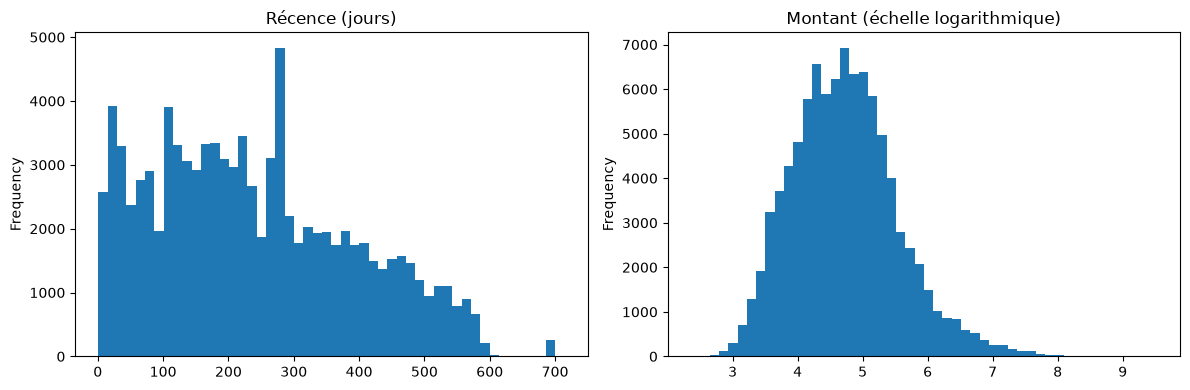

In [4]:
print("Répartition de la fréquence (nombre de commandes par client) :")
print(rfm["frequence"].value_counts().sort_index())

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
rfm["recence_jours"].plot.hist(bins=50, ax=axes[0])
axes[0].set_title("Récence (jours)")
np.log1p(rfm["montant"]).plot.hist(bins=50, ax=axes[1])
axes[1].set_title("Montant (échelle logarithmique)")
plt.tight_layout()
plt.show()

## 2. Préparation pour le clustering

- Le montant et la fréquence sont très asymétriques : on les passe au **logarithme** (`log1p`) pour que quelques très gros clients n'écrasent pas les autres.
- Les trois variables n'ont pas la même échelle (jours, nombre, réais) : on les **standardise** (moyenne 0, écart-type 1) pour que chacune pèse autant dans le calcul des distances du K-Means.

In [5]:
X = pd.DataFrame({
    "recence": rfm["recence_jours"],
    "frequence": np.log1p(rfm["frequence"]),
    "montant": np.log1p(rfm["montant"]),
})
X_scaled = StandardScaler().fit_transform(X)

## 3. Choix du nombre de segments

On teste K-Means de 2 à 7 segments avec deux critères :
- **la méthode du coude** (inertie) : on cherche le point où ajouter un segment n'apporte plus beaucoup ;
- **le score de silhouette** (entre -1 et 1) : plus il est élevé, mieux les segments sont séparés. Il est calculé sur un échantillon de 10 000 clients pour aller plus vite.

k = 2 : silhouette = 0.708
k = 3 : silhouette = 0.354
k = 4 : silhouette = 0.365
k = 5 : silhouette = 0.353
k = 6 : silhouette = 0.347
k = 7 : silhouette = 0.364


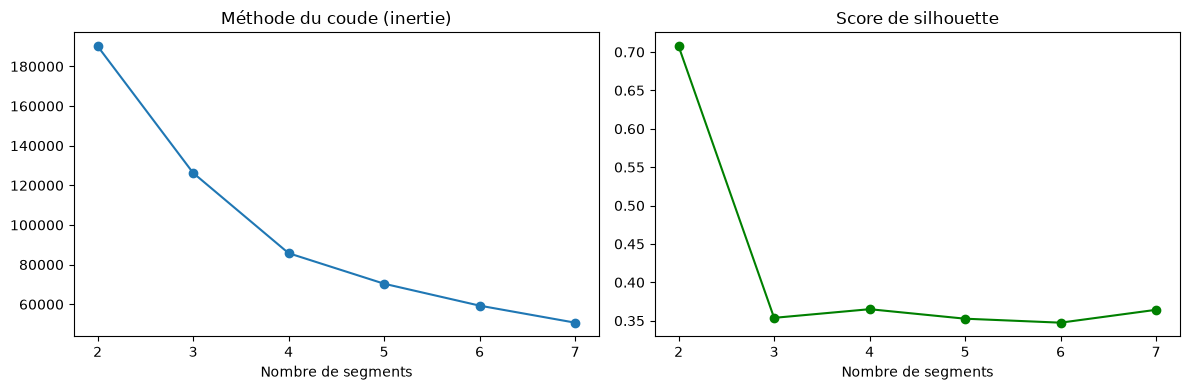

In [6]:
valeurs_k = range(2, 8)
inerties = []
silhouettes = []

for k in valeurs_k:
    modele = KMeans(n_clusters=k, random_state=42, n_init=10)
    etiquettes = modele.fit_predict(X_scaled)
    inerties.append(modele.inertia_)
    score = silhouette_score(X_scaled, etiquettes, sample_size=10000, random_state=42)
    silhouettes.append(score)
    print(f"k = {k} : silhouette = {score:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(list(valeurs_k), inerties, marker="o")
axes[0].set_title("Méthode du coude (inertie)")
axes[0].set_xlabel("Nombre de segments")
axes[1].plot(list(valeurs_k), silhouettes, marker="o", color="green")
axes[1].set_title("Score de silhouette")
axes[1].set_xlabel("Nombre de segments")
plt.tight_layout()
plt.show()

**Choix de k = 4** :
- k = 2 a la meilleure silhouette (0,71), mais il ne fait que séparer les clients qui ont commandé une fois de ceux qui ont commandé plusieurs fois (97 % / 3 %). Ce n'est pas assez fin pour le marketing.
- Parmi k = 3 à 7, **k = 4** a la meilleure silhouette (0,365) et correspond au **coude** de la courbe d'inertie : au-delà, ajouter un segment réduit peu l'inertie.
- 4 segments restent faciles à expliquer et à actionner.

**Remarque** : 97 % des clients n'ont passé qu'une commande (fréquence médiane = 1). La segmentation repose donc surtout sur la récence et le montant.

## 4. Segmentation finale

In [7]:
K = 4  # nombre de segments retenu

kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)
rfm["segment"] = kmeans.fit_predict(X_scaled)

profil = rfm.groupby("segment").agg(
    nb_clients=("customer_unique_id", "count"),
    recence_moyenne=("recence_jours", "mean"),
    frequence_moyenne=("frequence", "mean"),
    montant_moyen=("montant", "mean"),
    montant_total=("montant", "sum"),
)
profil["part_clients_pct"] = 100 * profil["nb_clients"] / profil["nb_clients"].sum()
profil["part_ca_pct"] = 100 * profil["montant_total"] / profil["montant_total"].sum()
profil.round(1)

,nb_clients,recence_moyenne,frequence_moyenne,montant_moyen,montant_total,part_clients_pct,part_ca_pct
segment,,,,,,,
0,27857,173.5,1.0,318.2,8864567.6,29.8,57.5
1,35699,147.8,1.0,69.1,2465268.5,38.2,16.0
2,27001,425.4,1.0,119.5,3225750.2,28.9,20.9
3,2801,220.3,2.1,308.5,864187.5,3.0,5.6


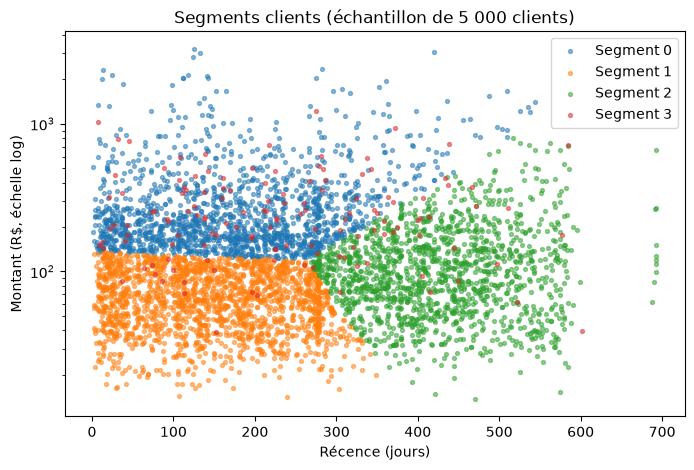

In [8]:
echantillon = rfm.sample(min(5000, len(rfm)), random_state=42)

plt.figure(figsize=(8, 5))
for s in sorted(echantillon["segment"].unique()):
    groupe = echantillon[echantillon["segment"] == s]
    plt.scatter(groupe["recence_jours"], groupe["montant"], s=8, alpha=0.5, label=f"Segment {s}")
plt.yscale("log")
plt.xlabel("Récence (jours)")
plt.ylabel("Montant (R$, échelle log)")
plt.title("Segments clients (échantillon de 5 000 clients)")
plt.legend()
plt.show()

## 5. Personas

| Segment | Clients | Récence moy. | Commandes moy. | Panier moy. | Part du CA |
|---|---|---|---|---|---|
| 0 — Gros acheteurs récents | 27 857 (29,8 %) | 174 j | 1,0 | 318 R$ | **57,5 %** |
| 1 — Petits acheteurs récents | 35 699 (38,2 %) | 148 j | 1,0 | 69 R$ | 16,0 % |
| 2 — Clients endormis | 27 001 (28,9 %) | 425 j | 1,0 | 120 R$ | 20,9 % |
| 3 — Clients fidèles | 2 801 (3,0 %) | 220 j | 2,1 | 309 R$ | 5,6 % |

On retient **3 personas prioritaires** :

**🛍️ Persona 1 — « Carla, la grosse acheteuse récente » (segment 0)**
A acheté il y a environ 6 mois une commande importante (318 R$ en moyenne), mais une seule fois. Ce segment pèse 57,5 % du chiffre d'affaires : **c'est le plus rentable à faire revenir**. Enjeu : transformer ce premier achat en deuxième commande.

**😴 Persona 2 — « Paulo, le client endormi » (segment 2)**
N'a rien commandé depuis plus d'un an (425 jours en moyenne), avec un panier moyen de 120 R$. Il est en train d'oublier la marque. Enjeu : le **réactiver** avant de le perdre définitivement.

**⭐ Persona 3 — « Ana, la cliente fidèle » (segment 3)**
Seulement 3 % des clients, mais déjà plus de 2 commandes en moyenne et un panier élevé (309 R$). C'est la preuve que le réachat est possible. Enjeu : la **récompenser** pour qu'elle continue et qu'elle recommande ShopPulse.

*Le segment 1 (petits paniers récents) n'est pas prioritaire : son panier moyen de 69 R$ rend une campagne coûteuse peu rentable. Il pourra être travaillé plus tard par des recommandations de produits complémentaires.*

## 6. Campagnes marketing chiffrées

| Campagne | Persona | Action |
|---|---|---|
| « Deuxième commande » | Carla (segment 0) | E-mail + bon de réduction de 10 % valable 30 jours sur une 2ᵉ commande |
| « On vous a manqué » | Paulo (segment 2) | E-mail de réactivation + livraison offerte |
| « Club fidélité » | Ana (segment 3) | Accès à un programme VIP : livraison offerte et ventes privées |

**Calcul** : gain attendu = clients ciblés × taux de conversion × panier moyen du segment.

**Hypothèses** (à valider avec l'équipe marketing) :
- le coût par client inclut l'envoi et le coût moyen de l'avantage offert, réparti sur tous les clients ciblés ;
- les taux de conversion sont prudents : 4 % pour une relance de clients récents, 2 % pour des clients endormis, 10 % pour des clients déjà fidèles ;
- le gain est un **chiffre d'affaires supplémentaire**, pas une marge : le bénéfice réel dépend de la commission de ShopPulse sur chaque vente.

In [9]:
# (nom, segment visé, coût par client en R$, taux de conversion)
campagnes = [
    ("Deuxième commande", 0, 1.50, 0.04),
    ("On vous a manqué", 2, 1.00, 0.02),
    ("Club fidélité", 3, 5.00, 0.10),
]

lignes = []
for nom, segment, cout_par_client, taux_conversion in campagnes:
    cible = profil.loc[segment, "nb_clients"]
    panier = profil.loc[segment, "montant_moyen"]
    cout = cible * cout_par_client
    gain = cible * taux_conversion * panier
    lignes.append({
        "campagne": nom,
        "segment": segment,
        "clients_cibles": int(cible),
        "cout_R$": round(cout),
        "gain_attendu_R$": round(gain),
        "ROI": round((gain - cout) / cout, 2) if cout > 0 else None,
    })

pd.DataFrame(lignes)

,campagne,segment,clients_cibles,cout_R$,gain_attendu_R$,ROI
0,Deuxième commande,0,27857,41786,354583,7.49
1,On vous a manqué,2,27001,27001,64515,1.39
2,Club fidélité,3,2801,14005,86419,5.17
